In [1]:
import sys
sys.path.append('../scripts')  # Adjust path as needed
from module import (
    count_usage_cases,
    create_degree_lists,
    count_cluster_wise,
    pre_vec,
    nordept,
    deptwisecount,
    normalized_dept_cluster,
    create_vector,
    create_vector2,
    create_vector3,
    clear_vec,
    culster_wise_val,
    create_con_table,
    chi_square_test,
    residuals_cal,
    create_group,
    normality_test,
    agostino_pearson_test,
    kruskal_wallis_test
)
from plots import ( grouped_bar_graph_horizontal_color, stacked_bar_graph, grouped_bar_graph_horizontal_color_white, boxplot,
    kde_plot,
    heatmap_plot
)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import matplotlib.patches as mpatches  # For patterns

In [95]:
from scipy import stats

In [3]:
file_path = '/Users/jesanahammed/Desktop/dataset/survey25.csv'
df_25 = pd.read_csv(file_path, encoding='latin1')

In [8]:
with open(file_path, 'r', encoding='latin1') as f:
    for i in range(5):
        print(f"Line {i+1}:")
        print(repr(f.readline()[:500]))

Line 1:
'ï»¿"Data Export Generated on Tue Oct 27 10:42:38 PDT 2026"\n'
Line 2:
'"Survey ID 13589662"\n'
Line 3:
'"Dashboard Name My Dashboard"\n'
Line 4:
'"Response ID","Response Status","IP Address","Timestamp (mm/dd/yyyy)","Duplicate","Time Taken to Complete (Seconds)","Seq. Number","External Reference","Custom Variable 1","Custom Variable 2","Custom Variable 3","Custom Variable 4","Custom Variable 5","Respondent Email","Email List","Country Code","Region","[Title_Text] Research on Generative AI at Mines","[Consent_Text] Thanks for clicking into this research study!Since 2023 researchers at the Colorado School of Mines have conducted annual surv'
Line 5:
'"","","","","","","","","","","","","","","","","","","","","","","","LLM-powered chatbotsÂ\xa0accessed through a browser or app (e.g. ChatGPT.com, Claude.ai, Gemini.google.com)","Search engines augmented with LLMs (e.g., Google search, Perplexity)","AI coding agentsÂ\xa0designed specifically to write, modify, and execute code (e.g.

In [20]:
# file_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26.csv'
# clean_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_clean.csv'

# with open(file_path, 'r', encoding='latin1', newline='') as infile:
#     lines = infile.readlines()

# with open(clean_path, 'w', encoding='latin1', newline='') as outfile:
#     outfile.writelines(lines[3:])

# print("Cleaned CSV saved!")

In [28]:
# file_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_clean.csv'
# df_26 = pd.read_csv(file_path, encoding='latin1')

In [25]:
with open(file_path, 'r', encoding='latin1') as f:
    for line_number, line in enumerate(f, start=1):
        if line_number == 691:
            print(repr(line))
            break

'"236517299","Completed","138.67.135.160","10/05/2026 18:26:05","0","699","1","","","","","","","","","US","CO","","","1","1","1","","5","5","4","4","2","3","1","3","1","3","5","4","2","1","1","1","1","1","1","1","1","1","1","1","0","0","0","1","1","1","0","1","1","1","1","1","1","1","1","1","1","1","[Something else] For my summer internship, I made a large knowledge base about my "proposed" project, so it could help me quickly make a very good project request.","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","","9","8","9","10","10","9","8","","","","","","","","","","","6","4","1","0","","0","","1","1","0","0","0","0","0","0","","","0","0","1","1","1","4","","","","","","","","","","","","","","","","","","","","0","0","0","0","0","0","0","0","0","0","0","0","0","1","1","1","0","0","7","70","","13","","","","","","","","","1","2","0","0","0","0","0","1","0","0","2","","2","5","keenan_manchester@mines.edu",""\n'


In [26]:
file_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_clean.csv'
repaired_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_repaired.csv'

# Read the CSV as raw text
with open(file_path, 'r', encoding='latin1', newline='') as f:
    content = f.read()

# Fix the unescaped quotation marks in this specific response
old_text = 'I feel like I am doing "okay" at keeping'
new_text = 'I feel like I am doing ""okay"" at keeping'

print("Occurrences found:", content.count(old_text))

content = content.replace(old_text, new_text)

content = content.replace(
    'my "proposed" project',
    'my ""proposed"" project'
)

# Save the repaired CSV as a separate file
with open(repaired_path, 'w', encoding='latin1', newline='') as f:
    f.write(content)

Occurrences found: 1


In [30]:
df_26 = pd.read_csv(repaired_path, encoding='latin1')
print("Dataset shape:", df_26.shape)
print("Number of columns:", len(df_26.columns))
df_26.head()

Dataset shape: (1214, 208)
Number of columns: 208


,Response ID,Response Status,IP Address,Timestamp (mm/dd/yyyy),Duplicate,Time Taken to Complete (Seconds),Seq. Number,External Reference,Custom Variable 1,Custom Variable 2,...,Unnamed: 198,Unnamed: 199,Unnamed: 200,Unnamed: 201,[Q57-C5-C69] What is your gender?,Unnamed: 203,[Q19] Are you a first-generation college student meaning that your parents or guardians did not complete a bachelor's degree from a four-year college or university?,[Q20] This ladder is a representation of socioeconomic status.At the top of the ladder are the people who are the best off those who have the most money most education and best jobs. At the bottom are the people who are the worst off those who have the least money least education worst jobs or no job. Where do you think your family stands on the ladder?,[Q38] You may now submit this survey fully anonymouslyÂ orÂ you can provide your Mines email.Providing your Mines email will help the the scientific community to understand impactful questions about how students reported GenAI use correlates with actual academic performance. InÂ Fall25 over 450 students opted in which is incredible for the scientific questions we hope to answer--thank you so much. If you were one of them please do share again this year! We can analyze how your responses changed in the last year and improve the granularity of our analysis.Â But this is fullyÂ optionalÂ and we genuinely appreciate your participation either way. If you wish to authorize the release of FERPA-protected records please provide your Mines email. If not click the Done button below to submit your response anonymously.AUTHORIZATION FOR RELEASE OF EDUCATION RECORDS FOR RESEARCH:Some of the individual student data the research team will access is protected as education records under the Family Educational Rights and Privacy Act (FERPA). FERPA is a federal law that gives students various rights with respect to their education records. Under FERPA you have the right to inspect and review your education records the right to request amendment of records you believe are inaccurate or misleading and the right to prevent disclosure of information from your education records without your prior consent subject to some specific exceptions.Â I hereby authorize Colorado School of Mines to disclose records of my transcript and grades (including overall GPA)Â upon request to exactly one trained PhD researcher in the research lab of Prof. C. Estelle Smith. This information will never be shared beyond that one PhD researcher and will have no academic repercussions. Even if you are a student actively or previously enrolled in Prof. Smiths or Fierros course(s) they willÂ notÂ view your survey response. Your FERPA-protected data may be released to this PhD researcher only after grades have been submitted at the end of the Fall 2026 semester.Â Provide your Mines email if you authorize the future release of your transcript and GPA:,Unnamed: 207
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Middle Eastern,White,Prefer not to answer,Something Else,NaN,Dynamic Comment,NaN,NaN,NaN,NaN
1,236420301.0,Completed,138.67.168.159,10/05/2026 07:50:17,0.0,261.0,1.0,NaN,NaN,NaN,...,0,1,0,0,2.0,NaN,NaN,NaN,NaN,NaN
2,236420308.0,Started,138.67.127.163,10/05/2026 07:50:20,0.0,1030.0,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,236420312.0,Completed,138.67.127.134,10/05/2026 07:50:22,0.0,658.0,1.0,NaN,NaN,NaN,...,0,1,0,0,1.0,NaN,NaN,NaN,NaN,NaN
4,236420337.0,Completed,138.67.135.160,10/05/2026 07:50:34,0.0,281.0,1.0,NaN,NaN,NaN,...,0,1,0,0,3.0,NaN,1.0,6.0,logan_hosmer@mines.edu,NaN


In [33]:
print(len(df_26['Response ID']))

1214


In [34]:
# Print all column names
for i, col in enumerate(df_26.columns):
    print(i, repr(col))

0 'Response ID'
1 'Response Status'
2 'IP Address'
3 'Timestamp (mm/dd/yyyy)'
4 'Duplicate'
5 'Time Taken to Complete (Seconds)'
6 'Seq. Number'
7 'External Reference'
8 'Custom Variable 1'
9 'Custom Variable 2'
10 'Custom Variable 3'
11 'Custom Variable 4'
12 'Custom Variable 5'
13 'Respondent Email'
14 'Email List'
15 'Country Code'
16 'Region'
17 '[Title_Text] Research on Generative AI at Mines'
18 '[Consent_Text] Thanks for clicking into this research study!Since 2023 researchers at the Colorado School of Mines have conducted annual surveys of students and faculty about Generative Artificial Intelligence (GenAI) on campus. This Fall we are continuing surveys across campus to understand how the situation is evolving over time. All current students (18+) faculty and staff at Mines are encouraged to take this survey! Weâ\x80\x99d love to hear from as many of you as possibleâ\x80\x93including those of you who have or have not taken prior surveys. The survey will close after Friday Octo

In [35]:
# Keep only rows where 'Response Status' is 'Completed'
df_26 = df_26[df_26['Response Status'] == 'Completed']

# Optional: reset index
df_26.reset_index(drop=True, inplace=True)

In [36]:
print(len(df_26['Response ID']))

1008


In [37]:
# Keep only rows where 'Response Status' is 'Completed'
df_25 = df_25[df_25['Response Status'] == 'Completed']

# Optional: reset index
df_25.reset_index(drop=True, inplace=True)

In [39]:
print(len(df_25['Response ID']))

1345


In [41]:
role_25 = df_25["Are you a current member of the Mines community?"]

In [42]:
role_25.value_counts()

Are you a current member of the Mines community?
1.0    1061
2.0     284
Name: count, dtype: int64

In [44]:
role_26 = df_26["[Consent_Student] Are you a current member of the Mines community?"]

In [45]:
role_26.value_counts()

[Consent_Student] Are you a current member of the Mines community?
1.0    727
2.0    281
Name: count, dtype: int64

## P(doom)

In [46]:
p_doom_var_25 = "If you would like, please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes, and 100 means that AI will definitely have catastrophic outcomes for humanity."

In [48]:
student_25 = df_25.loc[role_25 == 1, p_doom_var_25]
faculty_25 = df_25.loc[role_25 == 2, p_doom_var_25]

In [50]:
print(len(faculty_25))
print(faculty_25.isna().sum())

284
87


In [51]:
print(len(student_25))
print(student_25.isna().sum())

1061
254


In [53]:
faculty_25 = faculty_25.dropna()
print(len(faculty_25))
print(faculty_25.isna().sum())

197
0


In [54]:
student_25 = student_25.dropna()
print(len(student_25))
print(student_25.isna().sum())

807
0


In [55]:
student_25.dtype

dtype('O')

In [56]:
student_25 = pd.to_numeric(student_25, errors='coerce')

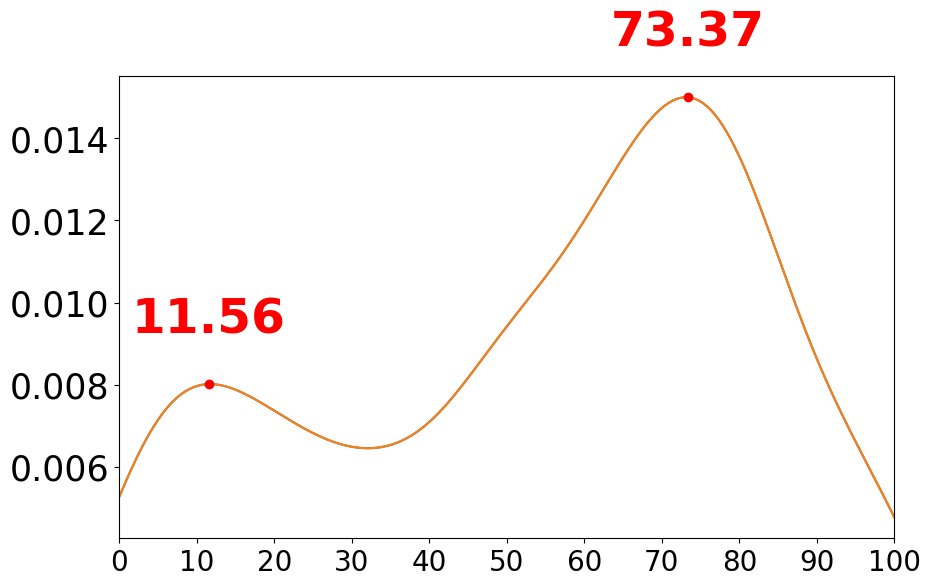

Peak values are at: [11.55778894 73.36683417]


In [57]:
kde_plot(student_25, 0, 100, 0.001, 11, 'Student P(doom) 2025.png', "Estimation", "Density") # peak font size 25

In [58]:
faculty_25.dtype

dtype('O')

In [59]:
faculty_25 = pd.to_numeric(faculty_25, errors='coerce')

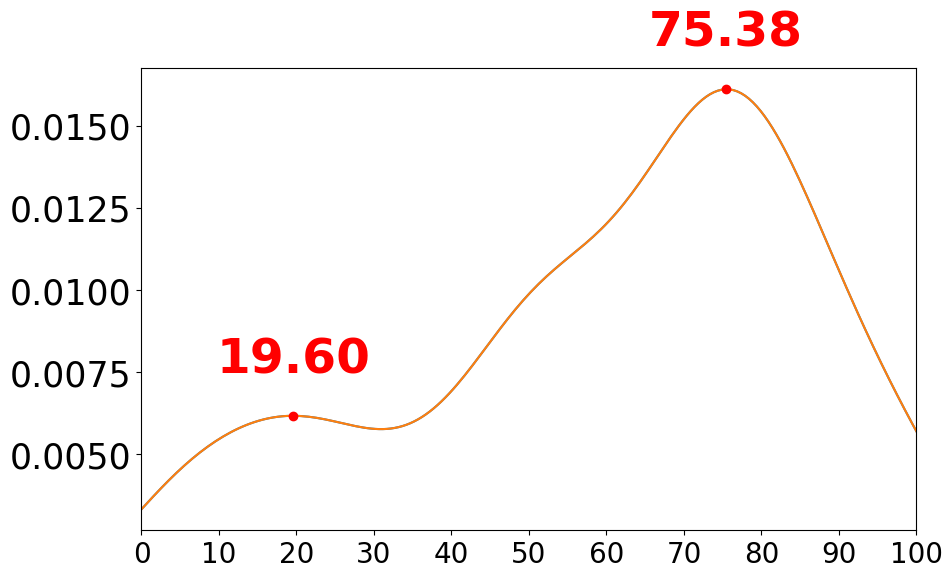

Peak values are at: [19.59798995 75.37688442]


In [92]:
kde_plot(faculty_25, 0, 100, 0.001, 11, 'Faculty P(doom) 2025.png', "Estimation", "Density") # peak font size 25

In [73]:
p_doom_var_26 = "[Q15] If you would like please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes and 100 means that AI will definitely have catastrophic outcomes for humanity."

In [74]:
student_26 = df_26.loc[role_26 == 1, p_doom_var_26]
faculty_26 = df_26.loc[role_26 == 2, p_doom_var_26]

In [75]:
print(len(faculty_26))
print(faculty_26.isna().sum())

281
25


In [76]:
print(len(student_26))
print(student_26.isna().sum())

727
73


In [77]:
faculty_26 = faculty_26.dropna()
print(len(faculty_26))
print(faculty_26.isna().sum())

256
0


In [78]:
student_26 = student_26.dropna()
print(len(student_26))
print(student_26.isna().sum())

654
0


In [79]:
student_26.dtype

dtype('O')

In [80]:
student_26 = pd.to_numeric(student_26, errors='coerce')

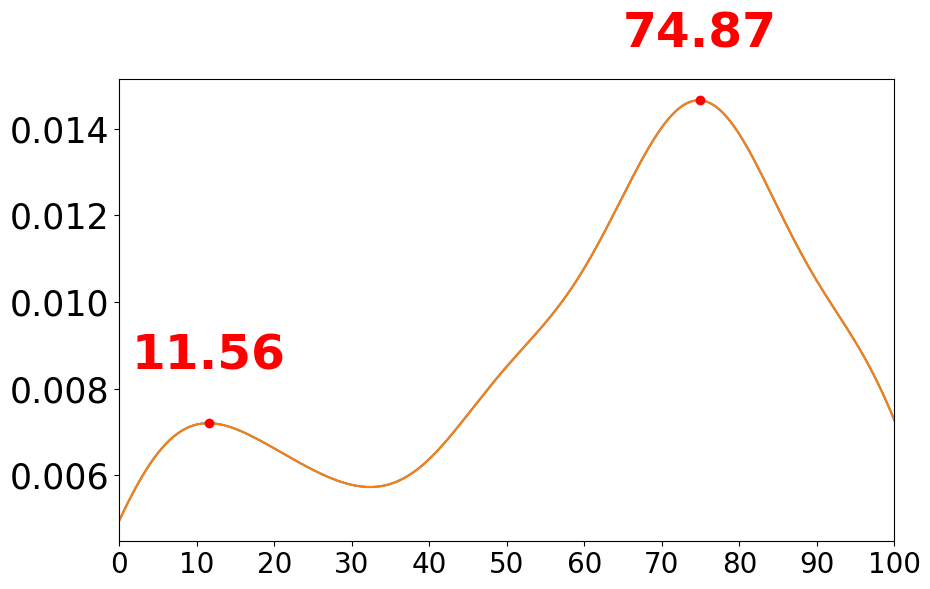

Peak values are at: [11.55778894 74.87437186]


In [93]:
kde_plot(student_26, 0, 100, 0.001, 11, 'Student P(doom) 2026.png', "Estimation", "Density") # peak font size 25

In [83]:
faculty_26.dtype

dtype('O')

In [84]:
faculty_26 = pd.to_numeric(faculty_26, errors='coerce')

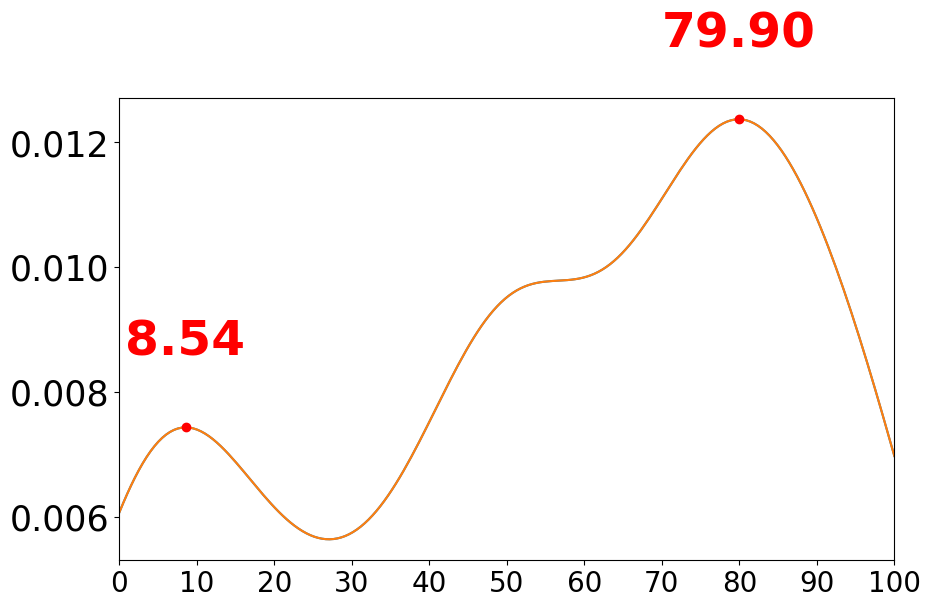

Peak values are at: [ 8.54271357 79.89949749]


In [85]:
kde_plot(faculty_26, 0, 100, 0.001, 11, 'Student P(doom) 2025.png', "Estimation", "Density") # peak font size 25

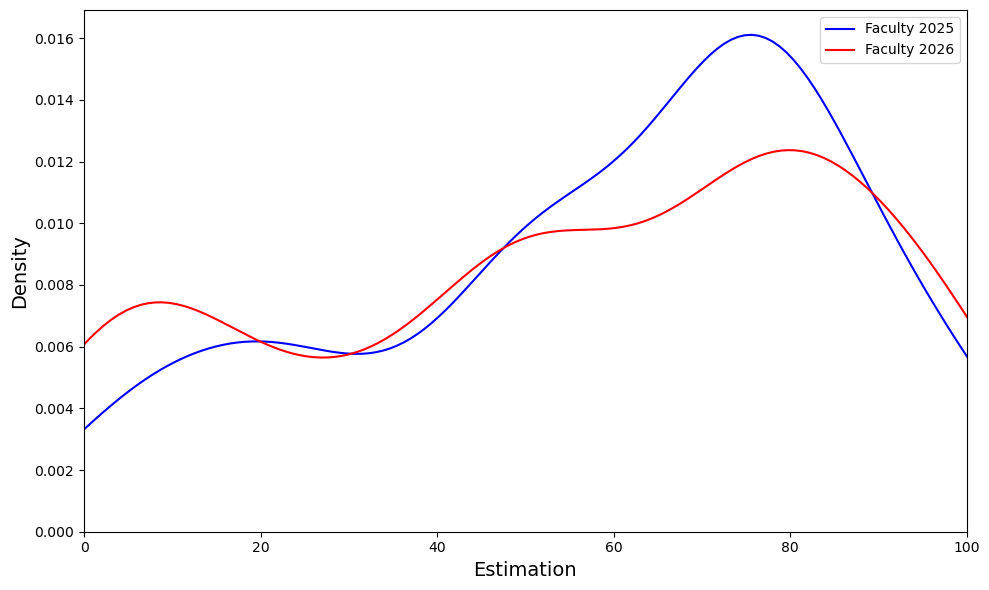

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.kdeplot(faculty_25, color='blue', label='Faculty 2025')
sns.kdeplot(faculty_26, color='red', label='Faculty 2026')
# sns.kdeplot(student_25, color='green', label='Student 2025')
# sns.kdeplot(student_26, color='purple', label='Student 2026')


plt.xlim(0, 100)
plt.xlabel("Estimation", fontsize=14)
plt.ylabel("Density", fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig('Faculty_Estimation_2025_2026.png', dpi=300)
plt.show()

In [90]:
print(student_25.describe())

count    794.000000
mean      54.090923
std       28.900930
min        0.000000
25%       30.000000
50%       60.000000
75%       75.000000
max      110.000000
Name: If you would like, please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes, and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64


In [91]:
print(student_26.describe())

count    648.000000
mean      57.473765
std       30.000555
min        0.000000
25%       33.000000
50%       65.000000
75%       80.000000
max      100.000000
Name: [Q15] If you would like please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64


In [96]:
# Remove missing values and ensure numeric data
x = student_25.dropna().astype(float)
y = student_26.dropna().astype(float)

# Descriptive statistics
print(f"2025: n={len(x)}, mean={x.mean():.4f}, SD={x.std(ddof=1):.4f}")
print(f"2026: n={len(y)}, mean={y.mean():.4f}, SD={y.std(ddof=1):.4f}")

# Welch's independent-samples t-test
result = stats.ttest_ind(y, x, equal_var=False)

# Mean difference: 2026 - 2025
diff = y.mean() - x.mean()

# Welch-Satterthwaite degrees of freedom
a = y.var(ddof=1) / len(y)
b = x.var(ddof=1) / len(x)
df = (a + b)**2 / (
    a**2 / (len(y) - 1) + b**2 / (len(x) - 1)
)

# 95% confidence interval for the mean difference
se = np.sqrt(a + b)
critical_t = stats.t.ppf(0.975, df)
ci_low = diff - critical_t * se
ci_high = diff + critical_t * se

# Hedges' g (pooled-SD standardized effect size)
n1, n2 = len(x), len(y)
pooled_sd = np.sqrt(
    ((n1 - 1) * x.var(ddof=1) +
     (n2 - 1) * y.var(ddof=1)) /
    (n1 + n2 - 2)
)
d = diff / pooled_sd
J = 1 - 3 / (4 * (n1 + n2) - 9)
hedges_g = J * d

print(f"Mean difference (2026 - 2025): {diff:.4f}")
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Welch's t({df:.2f}) = {result.statistic:.3f}")
print(f"p-value = {result.pvalue:.4g}")
print(f"Hedges' g = {hedges_g:.3f}")

2025: n=794, mean=54.0909, SD=28.9009
2026: n=648, mean=57.4738, SD=30.0006
Mean difference (2026 - 2025): 3.3828
95% CI: [0.3180, 6.4477]
Welch's t(1361.15) = 2.165
p-value = 0.03054
Hedges' g = 0.115


Students’ mean P(doom) ratings were significantly higher in 2026 (*M* = 57.47, *SD* = 30.00, *n* = 648) than in 2025 (*M* = 54.09, *SD* = 28.90, *n* = 794), according to Welch’s independent-samples *t*-test, *t*(1361.15) = 2.17, *p* = .031. The mean difference (2026 − 2025) was 3.38 points (95% CI [0.32, 6.45]), with a small standardized effect size (Hedges’ *g* = 0.115).

In [99]:
result = stats.mannwhitneyu(
    student_26.dropna(),
    student_25.dropna(),
    alternative="greater",
    method="asymptotic"
)

print("U statistic:", result.statistic)
print("p-value:", result.pvalue)

U statistic: 276524.0
p-value: 0.0070859908938513015


A one-sided Mann–Whitney U test indicated that student P(doom) ratings tended to be higher in 2026 than in 2025 (*U* = 276,524, *p* = .007). The magnitude of this difference was evaluated using an effect-size measure.

Student P(doom) ratings were higher in the 2026 survey than in the 2025 survey. The mean rating increased from 54.09 (*SD* = 28.90, *n* = 794) in 2025 to 57.47 (*SD* = 30.00, *n* = 648) in 2026, a difference of 3.38 points (95% CI [0.32, 6.45]). Welch’s independent-samples *t*-test indicated that this difference was statistically significant, *t*(1361.15) = 2.17, *p* = .031, although the standardized effect was small (Hedges’ *g* = 0.115). A one-sided Mann–Whitney U test also indicated that ratings tended to be higher in 2026 (*U* = 276,524, *p* = .007). Together, these findings suggest a modest upward shift in students’ P(doom) ratings between the two survey waves.

In [102]:
print(faculty_25.describe())
print(faculty_26.describe())

count    195.000000
mean      59.153846
std       27.269501
min        0.000000
25%       42.500000
50%       67.000000
75%       80.000000
max      100.000000
Name: If you would like, please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes, and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64
count    254.000000
mean      55.188976
std       31.433154
min        0.000000
25%       30.000000
50%       60.000000
75%       80.000000
max      100.000000
Name: [Q15] If you would like please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64


In [100]:
def welch_t_test(x, y):
    # Descriptive statistics
    print(f"2025: n={len(x)}, mean={x.mean():.4f}, SD={x.std(ddof=1):.4f}")
    print(f"2026: n={len(y)}, mean={y.mean():.4f}, SD={y.std(ddof=1):.4f}")
    
    # Welch's independent-samples t-test
    result = stats.ttest_ind(y, x, equal_var=False)
    
    # Mean difference: y - x
    diff = y.mean() - x.mean()

    # Welch-Satterthwaite degrees of freedom
    a = y.var(ddof=1) / len(y)
    b = x.var(ddof=1) / len(x)
    df = (a + b)**2 / (
        a**2 / (len(y) - 1) + b**2 / (len(x) - 1)
    )
    
    # 95% confidence interval for the mean difference
    se = np.sqrt(a + b)
    critical_t = stats.t.ppf(0.975, df)
    ci_low = diff - critical_t * se
    ci_high = diff + critical_t * se
    
    # Hedges' g (pooled-SD standardized effect size)
    n1, n2 = len(x), len(y)
    pooled_sd = np.sqrt(
        ((n1 - 1) * x.var(ddof=1) +
         (n2 - 1) * y.var(ddof=1)) /
        (n1 + n2 - 2)
    )
    d = diff / pooled_sd
    J = 1 - 3 / (4 * (n1 + n2) - 9)
    hedges_g = J * d
    
    print(f"Mean difference (2026 - 2025): {diff:.4f}")
    print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
    print(f"Welch's t({df:.2f}) = {result.statistic:.3f}")
    print(f"p-value = {result.pvalue:.4g}")
    print(f"Hedges' g = {hedges_g:.3f}")

In [106]:
x = faculty_25.dropna().astype(float)
y = faculty_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=195, mean=59.1538, SD=27.2695
2026: n=254, mean=55.1890, SD=31.4332
Mean difference (2026 - 2025): -3.9649
95% CI: [-9.4197, 1.4900]
Welch's t(440.32) = -1.429
p-value = 0.1538
Hedges' g = -0.133


In [115]:
def mann_w(x, y):
    result = stats.mannwhitneyu(
    y.dropna(),
    x.dropna(),
    alternative="greater",
    method="asymptotic"
    )

    print("U statistic:", result.statistic)
    print("p-value:", result.pvalue)

In [116]:
mann_w(faculty_25, faculty_26)

U statistic: 23354.5
p-value: 0.8503873063034366


## Harm Vs Beneficial

In [117]:
comp_task_var_26 = "[Q6] Your efficiency at completing tasks"

In [120]:
student_com_26 = df_26.loc[role_26 == 1, comp_task_var_26]

In [121]:
print(len(student_com_26))
print(student_com_26.isna().sum())

727
0


In [136]:
comp_task_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....2"

In [137]:
student_com_25 = df_25.loc[role_25 == 1, comp_task_var_25]

In [138]:
print(len(student_com_25))
print(student_com_25.isna().sum())

1061
0


In [139]:
def plot_distribution(data, title="Distribution", xlabel="Rating", bins=None):
    # Convert values to numeric and remove missing values
    values = pd.to_numeric(pd.Series(data).squeeze(), errors="coerce").dropna()

    plt.figure(figsize=(9, 5))

    if bins is None:
        sns.histplot(values, discrete=True, edgecolor="black")
    else:
        sns.histplot(values, bins=bins, edgecolor="black")

    plt.title(title, fontsize=14)
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel("Number of responses", fontsize=12)
    plt.tight_layout()
    plt.show()

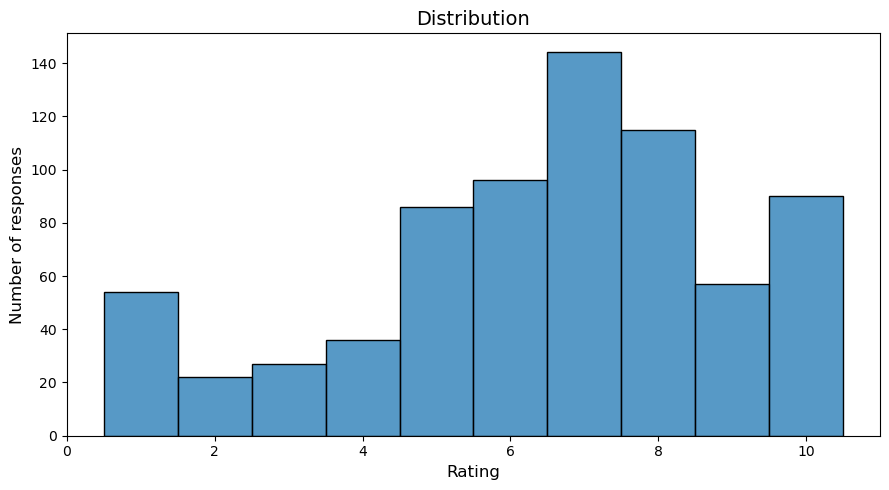

In [140]:
plot_distribution(student_com_26)

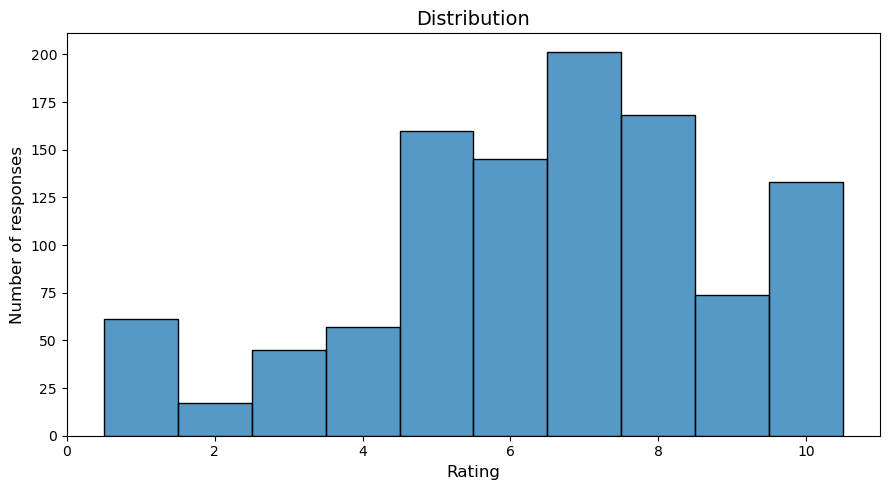

In [141]:
plot_distribution(student_com_25)

In [144]:
def rating_frequency(data, title="Rating Frequency", xlabel="Rating (1–10)"):
    ratings = pd.to_numeric(pd.Series(data).squeeze(), errors="coerce").dropna()

    frequencies = ratings.value_counts().reindex(range(1, 11), fill_value=0)

    plt.figure(figsize=(9, 5))
    bars = plt.bar(frequencies.index, frequencies.values, edgecolor="black")

    # Show frequency above each bar
    plt.bar_label(bars, fmt='%d', padding=3, fontsize=10)

    plt.xticks(range(1, 11))
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel("Frequency (number of responses)", fontsize=12)
    plt.title(title, fontsize=14)
    plt.ylim(0, max(frequencies.max() * 1.15, 1))
    plt.tight_layout()
    plt.show()

    print(frequencies)

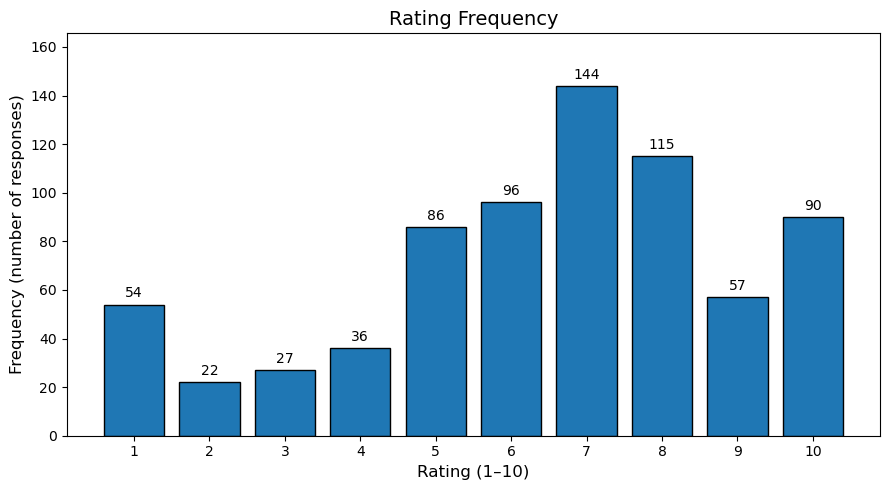

[Q6] Your efficiency at completing tasks
1      54
2      22
3      27
4      36
5      86
6      96
7     144
8     115
9      57
10     90
Name: count, dtype: int64


In [147]:
rating_frequency(student_com_26)

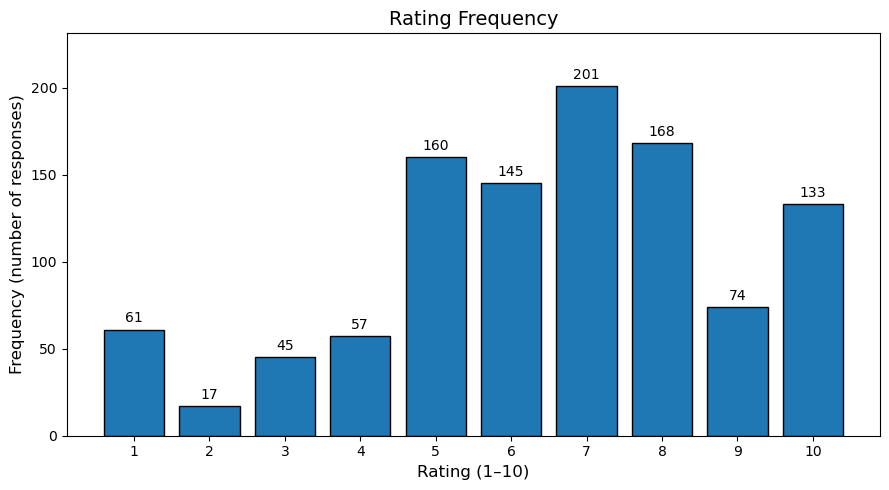

Please rate your current feelings on whether GenAI will be harmful or beneficial for....2
1      61
2      17
3      45
4      57
5     160
6     145
7     201
8     168
9      74
10    133
Name: count, dtype: int64


In [148]:
rating_frequency(student_com_25)

In [149]:
x = student_com_25.dropna().astype(float)
y = student_com_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=6.4797, SD=2.3817
2026: n=727, mean=6.4237, SD=2.5176
Mean difference (2026 - 2025): -0.0561
95% CI: [-0.2887, 0.1766]
Welch's t(1502.46) = -0.473
p-value = 0.6364
Hedges' g = -0.023


In [150]:
quality_task_var_26 = "[Q6] The quality of tasks you complete"

In [151]:
student_quality_26 = df_26.loc[role_26 == 1, quality_task_var_26]

In [152]:
print(len(student_quality_26))
print(student_quality_26.isna().sum())

727
0


In [153]:
quality_task_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....3"

In [154]:
student_quality_25 = df_25.loc[role_25 == 1, quality_task_var_25]

In [155]:
print(len(student_quality_25))
print(student_quality_25.isna().sum())

1061
0


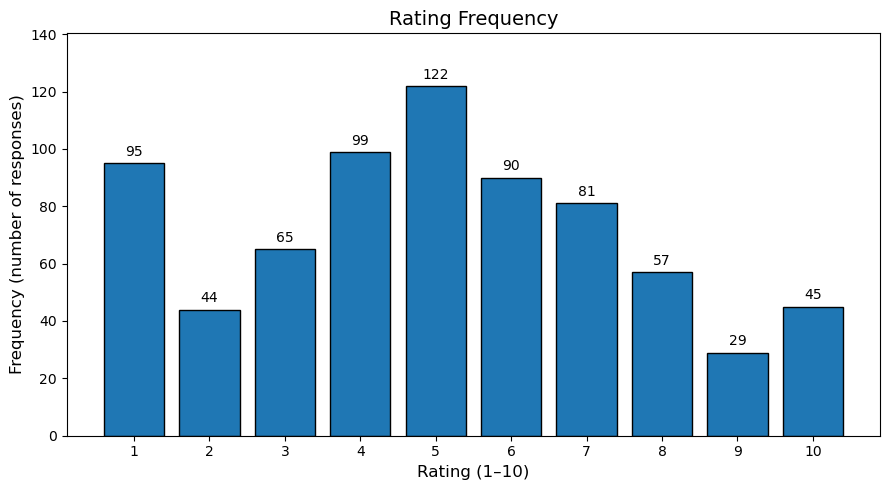

[Q6] The quality of tasks you complete
1      95
2      44
3      65
4      99
5     122
6      90
7      81
8      57
9      29
10     45
Name: count, dtype: int64


In [157]:
rating_frequency(student_quality_26)

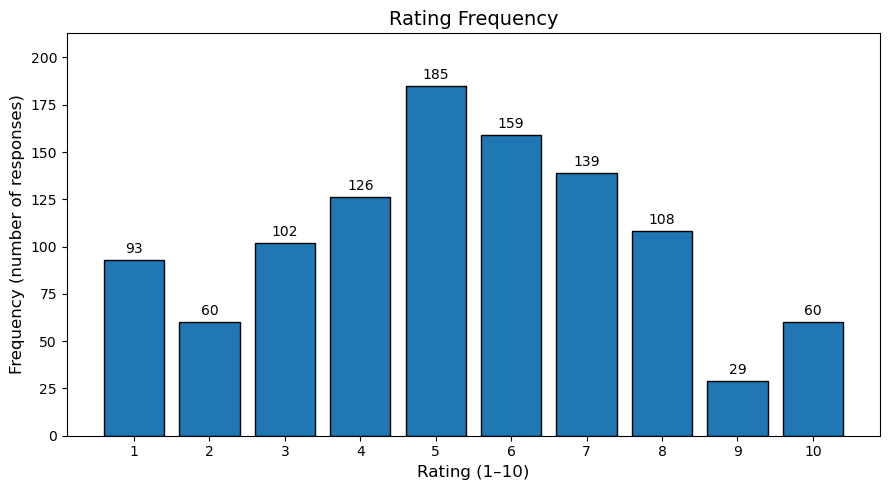

Please rate your current feelings on whether GenAI will be harmful or beneficial for....3
1      93
2      60
3     102
4     126
5     185
6     159
7     139
8     108
9      29
10     60
Name: count, dtype: int64


In [158]:
rating_frequency(student_quality_25)

In [160]:
x = student_quality_25.dropna().astype(float)
y = student_quality_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=5.2780, SD=2.4050
2026: n=727, mean=5.0316, SD=2.5687
Mean difference (2026 - 2025): -0.2464
95% CI: [-0.4828, -0.0100]
Welch's t(1491.51) = -2.044
p-value = 0.0411
Hedges' g = -0.100


In [161]:
society_var_26 = "[Q6] Society at large"

In [162]:
student_society_26 = df_26.loc[role_26 == 1, society_var_26]

In [163]:
print(len(student_society_26))
print(student_society_26.isna().sum())

727
0


In [165]:
society_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....6"

In [166]:
student_society_25 = df_25.loc[role_25 == 1, society_var_25]

In [167]:
print(len(student_society_25))
print(student_society_25.isna().sum())

1061
0


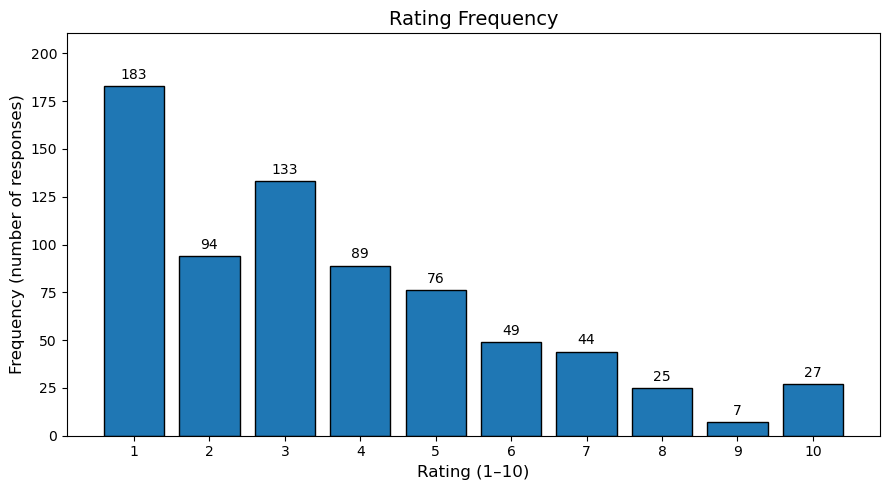

[Q6] Society at large
1     183
2      94
3     133
4      89
5      76
6      49
7      44
8      25
9       7
10     27
Name: count, dtype: int64


In [168]:
rating_frequency(student_society_26)

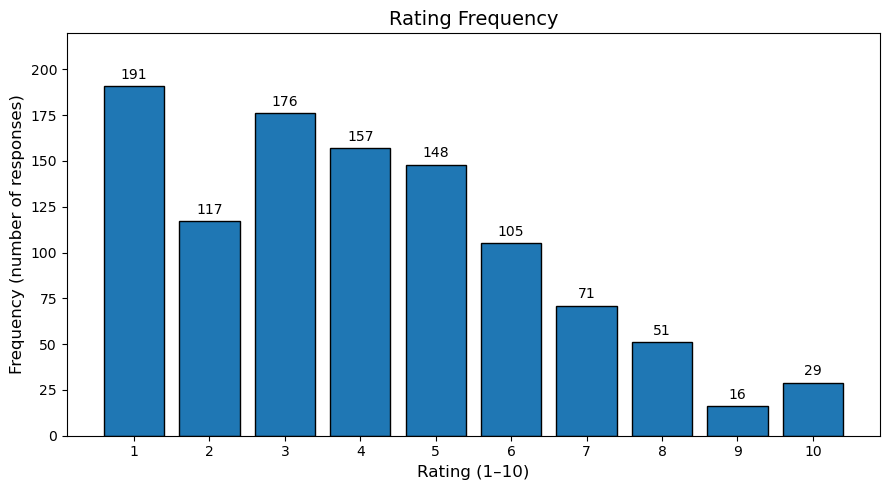

Please rate your current feelings on whether GenAI will be harmful or beneficial for....6
1     191
2     117
3     176
4     157
5     148
6     105
7      71
8      51
9      16
10     29
Name: count, dtype: int64


In [169]:
rating_frequency(student_society_25)

In [170]:
x = student_society_25.dropna().astype(float)
y = student_society_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=4.0434, SD=2.3448
2026: n=727, mean=3.6327, SD=2.4260
Mean difference (2026 - 2025): -0.4106
95% CI: [-0.6366, -0.1846]
Welch's t(1524.94) = -3.563
p-value = 0.0003772
Hedges' g = -0.173


In [171]:
learning_var_26 = "[Q6] Your learning during higher education"

In [172]:
student_lear_26 = df_26.loc[role_26 == 1, learning_var_26]

In [173]:
print(len(student_lear_26))
print(student_lear_26.isna().sum())

727
0


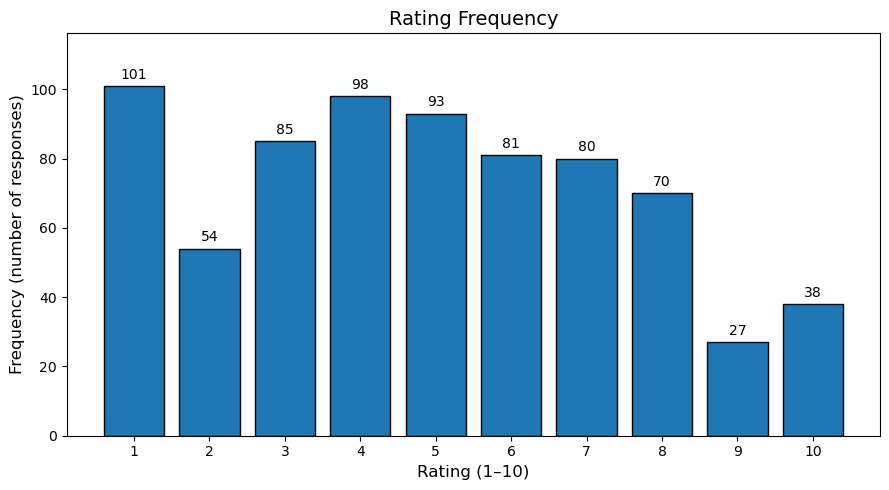

[Q6] Your learning during higher education
1     101
2      54
3      85
4      98
5      93
6      81
7      80
8      70
9      27
10     38
Name: count, dtype: int64


In [174]:
rating_frequency(student_lear_26)

In [175]:
learning_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....1"

In [176]:
student_lear_25 = df_25.loc[role_25 == 1, learning_var_25]

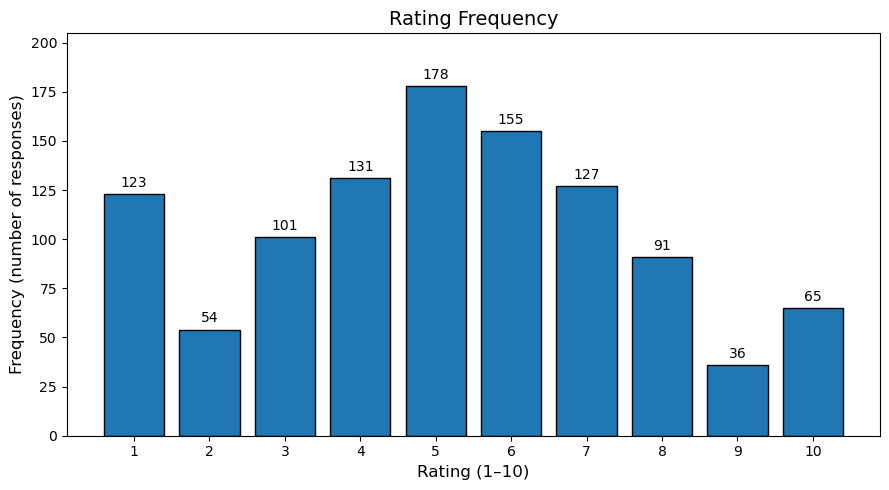

Please rate your current feelings on whether GenAI will be harmful or beneficial for....1
1     123
2      54
3     101
4     131
5     178
6     155
7     127
8      91
9      36
10     65
Name: count, dtype: int64


In [177]:
rating_frequency(student_lear_25)

In [179]:
x = student_lear_25.dropna().astype(float)
y = student_lear_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=5.1546, SD=2.5041
2026: n=727, mean=4.8831, SD=2.6093
Mean difference (2026 - 2025): -0.2715
95% CI: [-0.5139, -0.0291]
Welch's t(1517.49) = -2.197
p-value = 0.0282
Hedges' g = -0.107


Statistical Significance ($p = 0.0282$): Since $p < 0.05$, there is a statistically significant decrease in rating from 2025 to 2026. Sampling noise alone is an unlikely explanation for this drop.

Precision ($95\%\text{ CI } = [-0.5139, -0.0291]$): The interval stays entirely below zero, confirming a true negative shift. It tells us we can be 95% confident that the true population decrease is between roughly $0.03$ and $0.51$ points.

Practical Impact ($\text{Hedges' } g = -0.107$): Despite being statistically significant, the effect size is tiny ($\vert{}g\vert{} < 0.20$). A change of less than a third of a point on a scale where the standard deviation is over $2.5$ represents a very minor real-world shift.